## Exercise: Monte Carlo

In [90]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt
def bs_call(S0,K,T,r,sigma):
    d1 = (np.log(S0/K) + (r + 0.5*sigma**2)*T)/(sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    return S0*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)

In [91]:
S0 = 100
K= 100
mu = 0.08
r = 0.03
sigma = 0.5
T = 1
dt = 1/252
rng = np.random.default_rng(42)

iid_norm = rng.normal(0,1,(10000,252))
log_increase_rate_mu = (mu-0.5*sigma**2)*dt + sigma*np.sqrt(dt)*iid_norm
paths_mu = np.exp(np.log(S0) + np.cumsum(log_increase_rate_mu,axis=1))
print(paths_mu.nbytes/1024**2)
print(paths_mu[:,-1].mean())

log_increase_rate_r = (r-0.5*sigma**2)*dt + sigma*np.sqrt(dt)*iid_norm
paths_r = np.exp(np.log(S0) + np.cumsum(log_increase_rate_r,axis=1))
print(paths_r[:,-1].mean())


19.22607421875
108.87905875023726
103.56896439516763


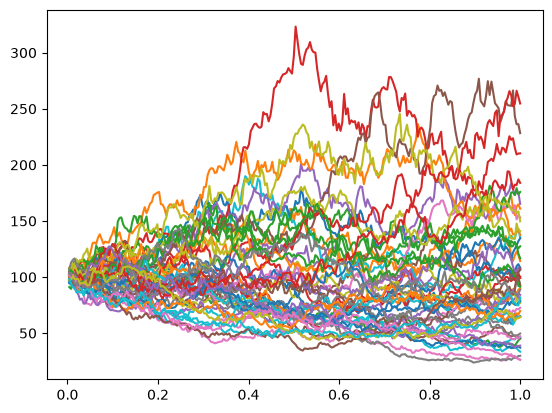

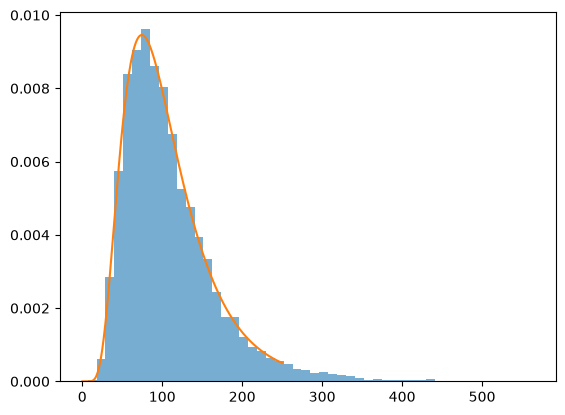

In [92]:
import scipy
import scipy.stats


x = np.arange(1,253)/252
y = paths_mu[:50,:].T
plt.plot(x,y)
plt.show()

plt.hist(paths_mu[:,-1],bins=50,density=True,alpha=0.6)
x1 = np.linspace(0,250,1000)
plt.plot(x1,scipy.stats.lognorm.pdf(x1,s=sigma*np.sqrt(T),scale=S0*np.exp((mu-0.5*sigma**2)*T)))
plt.show()

In [93]:
MC_price = np.exp(-r*T)*np.maximum(paths_r[:,-1] - K,0).mean()
print(MC_price)
MC_price1 = np.exp(-r*T)*np.maximum(paths_mu[:,-1] - K,0).mean()
print(MC_price1)

21.347333257916898
24.656769717696676


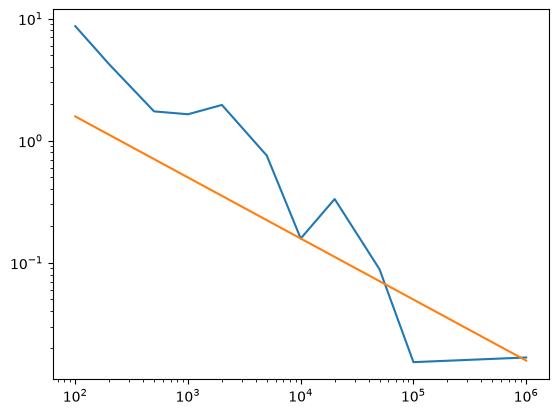

In [94]:
rng = np.random.default_rng(42)
path_size = np.array([100,200,500,1000,2000,5000,10000,20000,50000,100000,1000000])
terminal_prices = S0*np.exp((r-0.5*sigma**2)*T+sigma*np.sqrt(T)*rng.normal(0,1,1000000))
price_MC = np.array([np.exp(-r*T)*np.maximum(terminal_prices[:x] - K,0).mean() for x in path_size])
price_bs = bs_call(S0,K,T,r,sigma)
error = np.abs(price_MC - price_bs)
plt.loglog(path_size, error)
c = error[6]*np.sqrt(path_size[6])
plt.loglog(path_size, c/np.sqrt(path_size))
plt.show()

In [95]:
import time
n_path = 2000
n_step = 252
dt = T/n_step

t0 = time.time()
rng = np.random.default_rng(1)
path_for = np.zeros((n_path, n_step+1))
path_for[:,0] = S0
for i in range(n_path):
    s = S0
    for j in range(n_step):
        z = rng.normal(0,1)
        s = s * np.exp((mu-0.5*sigma**2)*dt + sigma*np.sqrt(dt)*z)
        path_for[i,j+1] = s
t_for = time.time()-t0

t1 = time.time()
rng = np.random.default_rng(1)
z = rng.standard_normal((n_path,n_step))
log_ret = (mu-0.5*sigma**2)*dt + sigma*np.sqrt(dt)*z
path_vec = np.zeros((n_path, n_step+1))
path_vec[:,0] = S0
path_vec[:,1:] = S0*np.exp(np.cumsum(log_ret,axis=1))

t_vec = time.time() - t1

print(np.allclose(path_for,path_vec))
print(t_for)
print(t_vec)

True
1.8478729724884033
0.019971609115600586
